In [ ]:
#| default_exp data

# Exploring LJSpeech

> LJSpeech download and transcripts.

[LJSpeech](https://keithito.com/LJ-Speech-Dataset/) is 13,100 short clips of one speaker reading
public-domain audiobooks: about 24 hours of audio, plus a transcript for each clip.
It is the standard first dataset for training a single-speaker TTS model like Piper.

The download is ~2.6 GB compressed and ~3.6 GB extracted. It goes into `data/`, which is gitignored.

In [ ]:
import librosa
import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
from IPython.display import Audio, display

In [ ]:
#| export
import tarfile
import urllib.request

import pandas as pd
from tqdm.auto import tqdm

from text_to_speech.core import DATA

In [ ]:
#| export
URL = "https://data.keithito.com/data/speech/LJSpeech-1.1.tar.bz2"
LJSPEECH = DATA / "LJSpeech-1.1"
WAVS = LJSPEECH / "wavs"

## Download and extract

In [ ]:
#| export
def download_ljspeech():
    "Download and extract LJSpeech into `DATA`, skipping whichever step is already done."
    archive = DATA / "LJSpeech-1.1.tar.bz2"
    DATA.mkdir(exist_ok=True)
    if not archive.exists():
        with tqdm(unit="B", unit_scale=True, desc="Downloading") as bar:

            def report(block_num, block_size, total_size):
                bar.total = total_size
                bar.update(block_size)

            urllib.request.urlretrieve(URL, archive, reporthook=report)
    if not WAVS.exists():
        with tarfile.open(archive, "r:bz2") as tar:
            tar.extractall(DATA, filter="data")

In [ ]:
download_ljspeech()  # Extracting takes a few minutes
print(f"{len(list(WAVS.glob('*.wav'))):,} wav files in {WAVS}")

13,100 wav files in /Users/henrydashwood/text-to-speech/data/LJSpeech-1.1/wavs


## The transcripts

`metadata.csv` has one line per clip, `|`-separated: the clip id, the raw transcript,
and a normalised transcript with numbers and abbreviations spelled out.
This is the same `filename|text` format Piper's trainer expects.

In [ ]:
#| export
def metadata():
    "One row per clip: id, text, normalized_text, path."
    df = pd.read_csv(
        LJSPEECH / "metadata.csv",
        sep="|",
        header=None,
        names=["id", "text", "normalized_text"],
        quoting=3,  # No quote handling: the transcripts contain literal quote marks
    )
    df["normalized_text"] = df["normalized_text"].fillna(df["text"])
    df["path"] = df["id"].map(lambda i: WAVS / f"{i}.wav")
    return df

In [ ]:
df = metadata()
print(len(df), "clips")
df.head(10)

13100 clips


,id,text,normalized_text,path
0,LJ001-0001,"Printing, in the only sense with which we are ...","Printing, in the only sense with which we are ...",/Users/henrydashwood/text-to-speech/data/LJSpe...
1,LJ001-0002,in being comparatively modern.,in being comparatively modern.,/Users/henrydashwood/text-to-speech/data/LJSpe...
2,LJ001-0003,For although the Chinese took impressions from...,For although the Chinese took impressions from...,/Users/henrydashwood/text-to-speech/data/LJSpe...
3,LJ001-0004,"produced the block books, which were the immed...","produced the block books, which were the immed...",/Users/henrydashwood/text-to-speech/data/LJSpe...
4,LJ001-0005,the invention of movable metal letters in the ...,the invention of movable metal letters in the ...,/Users/henrydashwood/text-to-speech/data/LJSpe...
5,LJ001-0006,"And it is worth mention in passing that, as an...","And it is worth mention in passing that, as an...",/Users/henrydashwood/text-to-speech/data/LJSpe...
6,LJ001-0007,"the earliest book printed with movable types, ...","the earliest book printed with movable types, ...",/Users/henrydashwood/text-to-speech/data/LJSpe...
7,LJ001-0008,has never been surpassed.,has never been surpassed.,/Users/henrydashwood/text-to-speech/data/LJSpe...
8,LJ001-0009,"Printing, then, for our purpose, may be consid...","Printing, then, for our purpose, may be consid...",/Users/henrydashwood/text-to-speech/data/LJSpe...
9,LJ001-0010,"Now, as all books not primarily intended as pi...","Now, as all books not primarily intended as pi...",/Users/henrydashwood/text-to-speech/data/LJSpe...


In [ ]:
# Where normalisation changed something.
changed = df[df["text"] != df["normalized_text"]]
print(f"{len(changed):,} of {len(df):,} transcripts were normalised\n")
for _, row in changed.head(5).iterrows():
    print("raw:       ", row["text"])
    print("normalised:", row["normalized_text"])
    print()

1,505 of 13,100 transcripts were normalised

raw:        the earliest book printed with movable types, the Gutenberg, or "forty-two line Bible" of about 1455,
normalised: the earliest book printed with movable types, the Gutenberg, or "forty-two line Bible" of about fourteen fifty-five,

raw:        But the first Bible actually dated (which also was printed at Maintz by Peter Schoeffer in the year 1462)
normalised: But the first Bible actually dated (which also was printed at Maintz by Peter Schoeffer in the year fourteen sixty-two)

raw:        In 1465 Sweynheim and Pannartz began printing in the monastery of Subiaco near Rome,
normalised: In fourteen sixty-five Sweynheim and Pannartz began printing in the monastery of Subiaco near Rome,

raw:        They printed very few books in this type, three only; but in their very first books in Rome, beginning with the year 1468,
normalised: They printed very few books in this type, three only; but in their very first books in Rome, beginning 

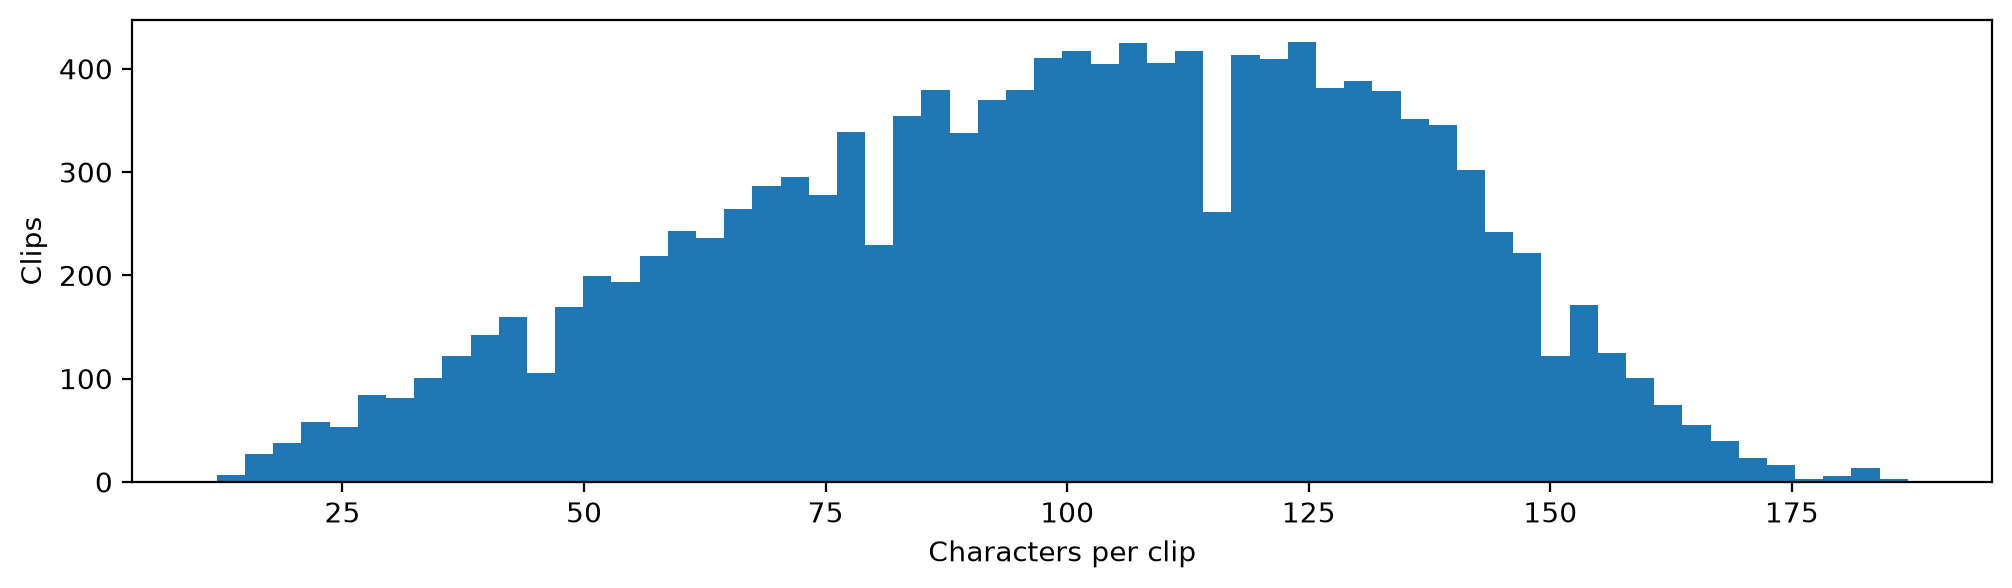

,n_chars,n_words
count,13100.0,13100.0
mean,99.9,17.0
std,34.0,6.1
min,12.0,1.0
25%,76.0,13.0
50%,102.0,17.0
75%,126.0,21.0
max,187.0,39.0


In [ ]:
df["n_chars"] = df["normalized_text"].str.len()
df["n_words"] = df["normalized_text"].str.split().str.len()

plt.figure(figsize=(12, 3))
plt.hist(df["n_chars"], bins=60)
plt.xlabel("Characters per clip")
plt.ylabel("Clips")
plt.show()

df[["n_chars", "n_words"]].describe().round(1)

## The audio

In [ ]:
info = sf.info(df["path"][0])
print(info)

/Users/henrydashwood/text-to-speech/data/LJSpeech-1.1/wavs/LJ001-0001.wav
samplerate: 22050 Hz
channels: 1
duration: 9.655 s
format: WAV (Microsoft) [WAV]
subtype: Signed 16 bit PCM [PCM_16]


In [ ]:
# Reading the header of every file is fast enough to do in one go.
durations = []
for path in tqdm(df["path"], desc="Reading headers"):
    durations.append(sf.info(path).duration)
df["duration"] = durations

total_hours = df["duration"].sum() / 3600
print(f"Total: {total_hours:.1f} hours")
df["duration"].describe().round(2)

Total: 23.9 hours


Reading headers: 100%|##########| 13100/13100 [00:02<00:00, 5419.28it/s]


count    13100.00
mean         6.57
std          2.19
min          1.11
25%          4.99
50%          6.76
75%          8.39
max         10.10
Name: duration, dtype: float64

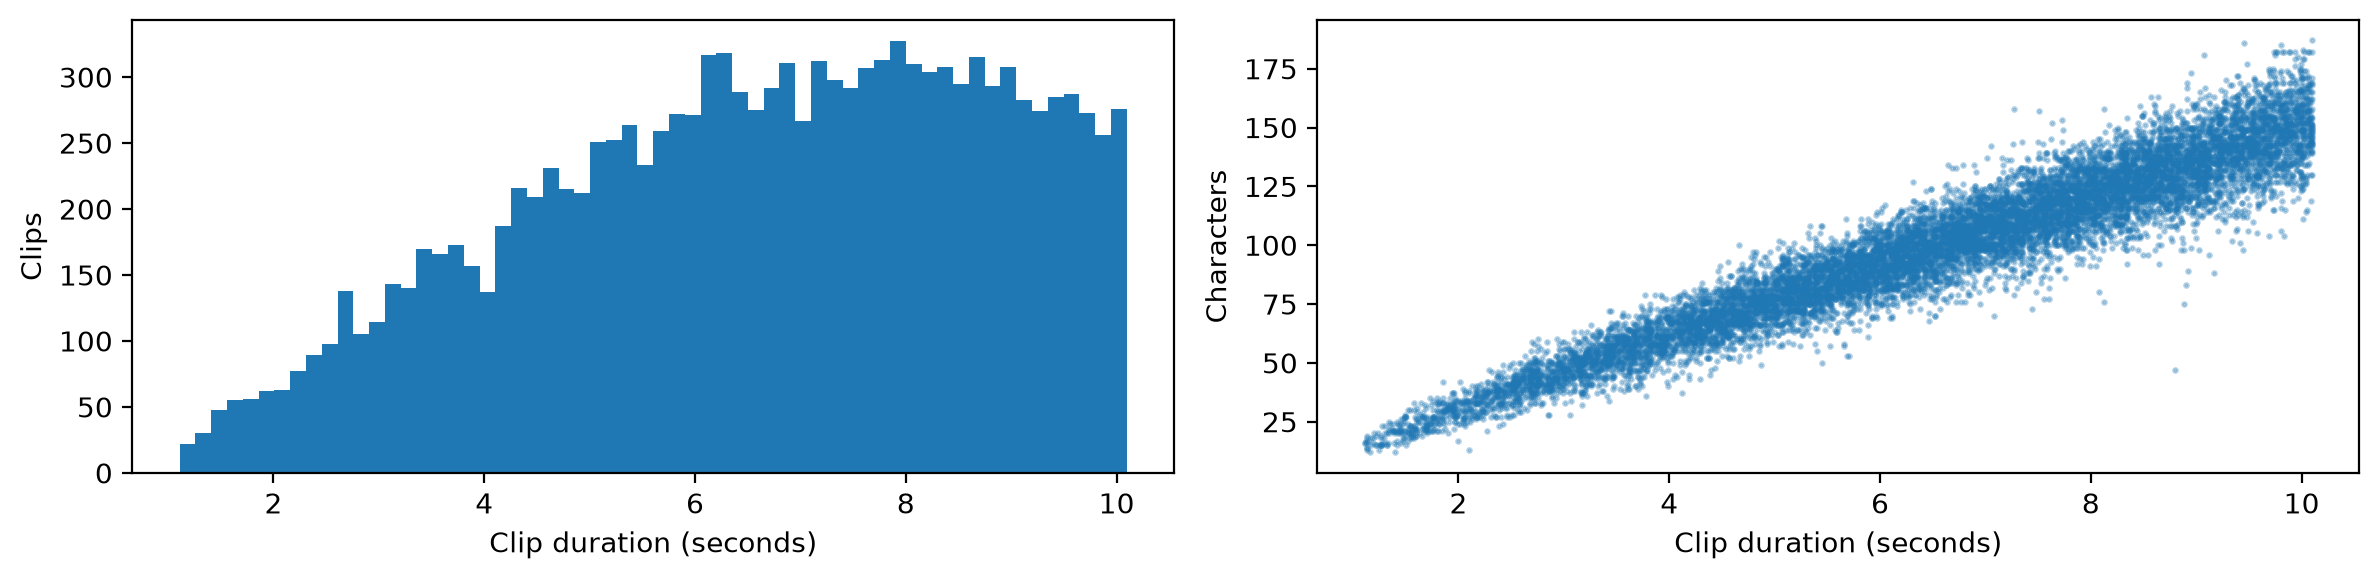

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))

axes[0].hist(df["duration"], bins=60)
axes[0].set_xlabel("Clip duration (seconds)")
axes[0].set_ylabel("Clips")

# Speaking rate: characters per second is a useful sanity check for outliers.
axes[1].scatter(df["duration"], df["n_chars"], s=2, alpha=0.3)
axes[1].set_xlabel("Clip duration (seconds)")
axes[1].set_ylabel("Characters")

plt.tight_layout()
plt.show()

## Listen to a clip

In [ ]:
row = df.iloc[0]
audio, sample_rate = sf.read(row["path"], dtype="float32")

print(row["id"])
print(row["normalized_text"])
print(f"{len(audio):,} samples at {sample_rate} Hz = {len(audio) / sample_rate:.2f} s")

Audio(audio, rate=sample_rate)

LJ001-0001
Printing, in the only sense with which we are at present concerned, differs from most if not from all the arts and crafts represented in the Exhibition
212,893 samples at 22050 Hz = 9.66 s


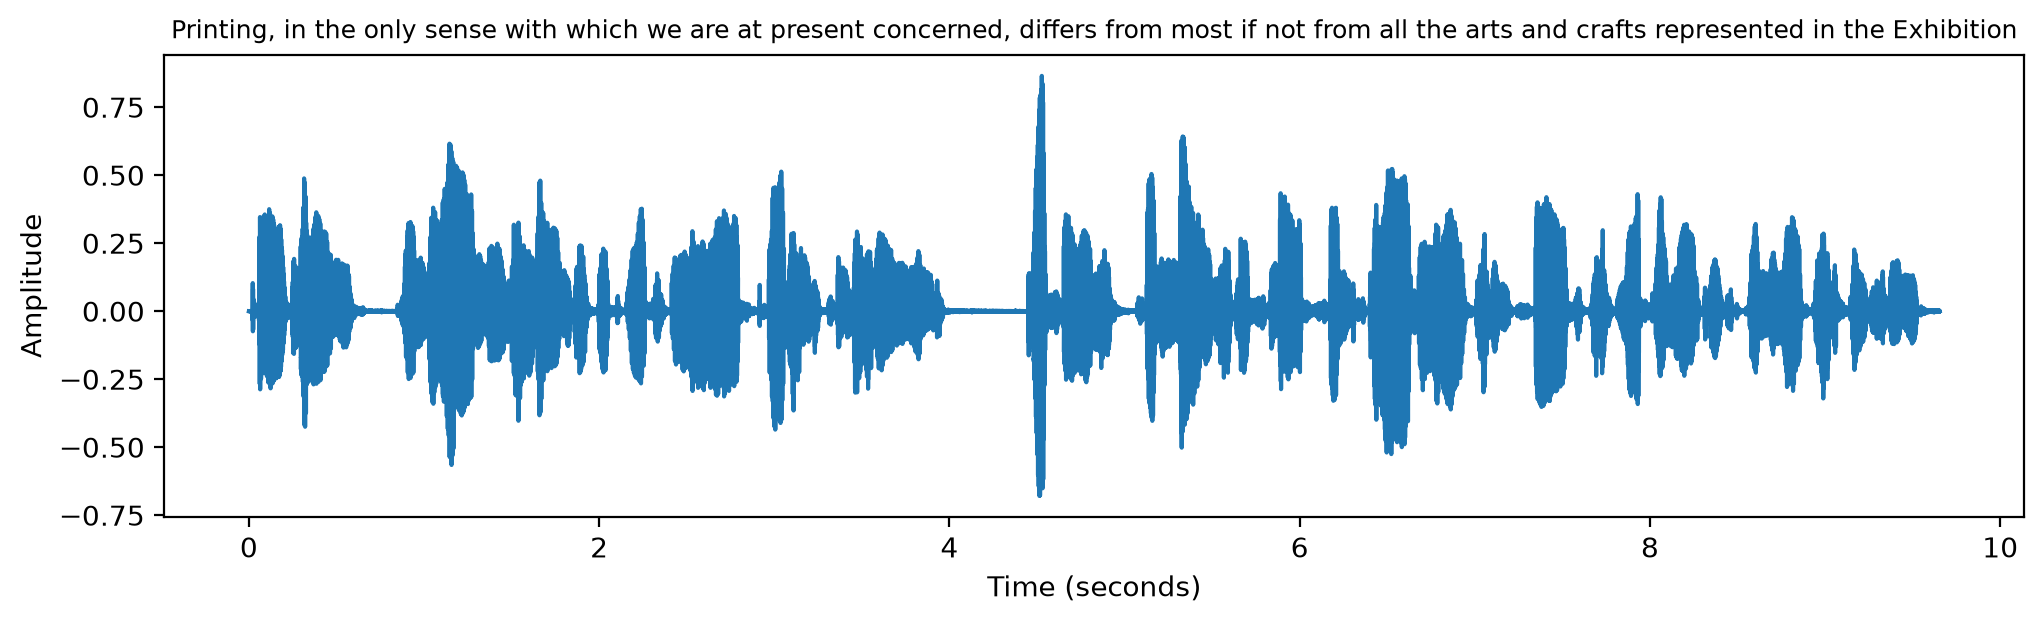

In [ ]:
time = np.arange(len(audio)) / sample_rate

plt.figure(figsize=(12, 3))
plt.plot(time, audio)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title(row["normalized_text"], fontsize=9)
plt.show()

## Spectrogram

The same picture as at the end of notebook 00, now for LJSpeech. Note the frequency axis stops at 11 kHz: half the
22.05 kHz sample rate, the highest frequency these recordings can hold.

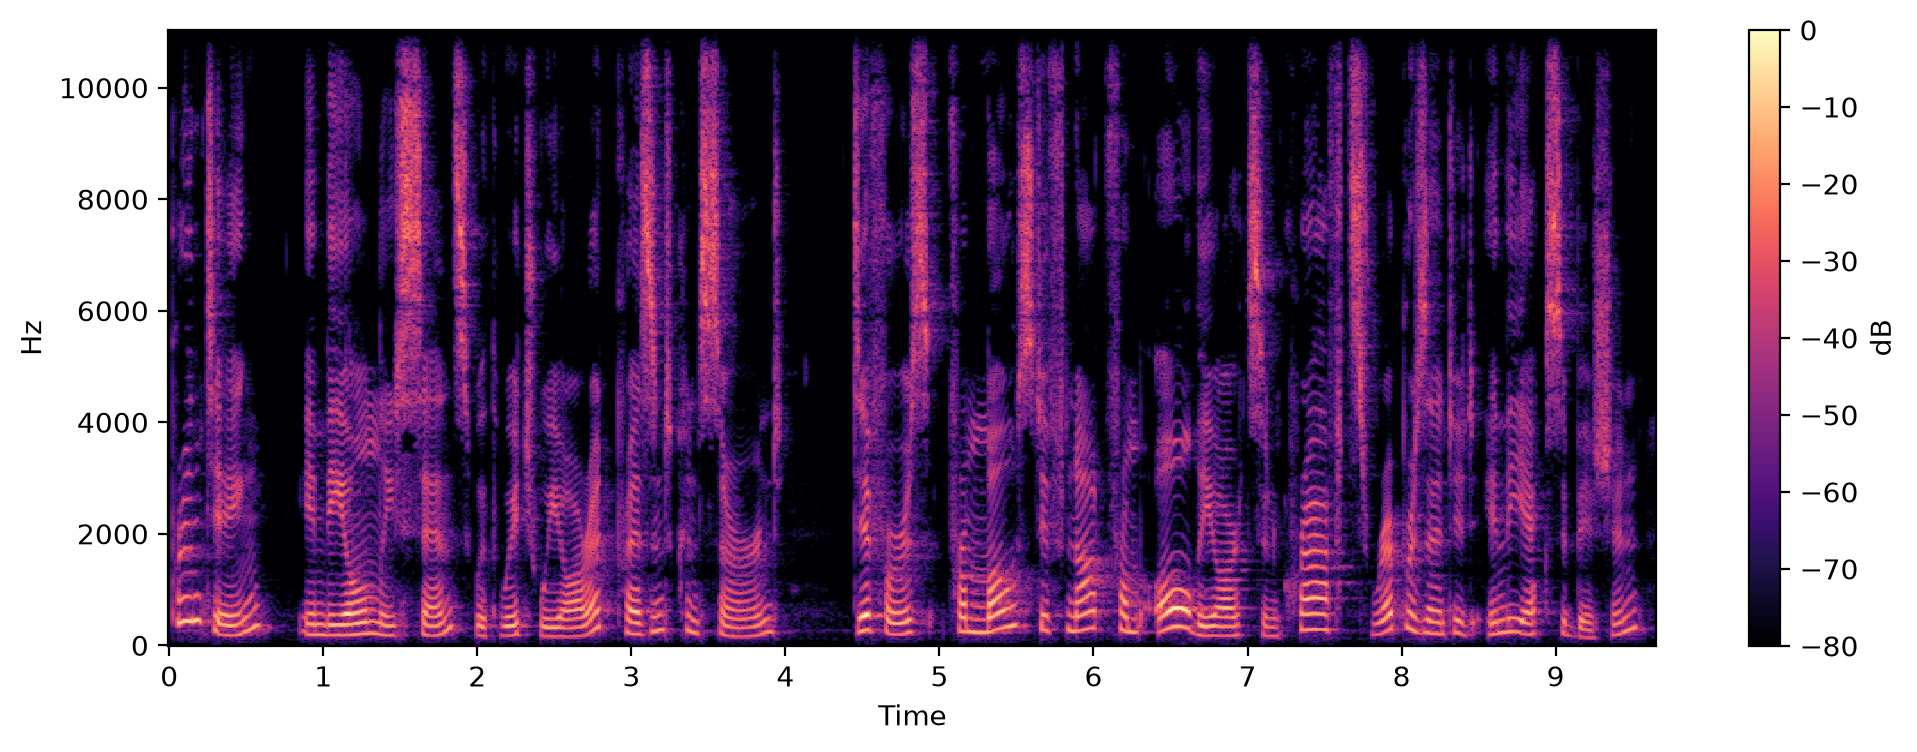

In [ ]:
hop = 256
spectrogram = np.abs(librosa.stft(audio, n_fft=1024, hop_length=hop))

plt.figure(figsize=(12, 4))
librosa.display.specshow(
    librosa.amplitude_to_db(spectrogram, ref=np.max), sr=sample_rate, hop_length=hop, x_axis="time", y_axis="hz"
)
plt.colorbar(label="dB")
plt.show()

In [ ]:
# Play a few more at random to get a feel for the voice.
for _, r in df.sample(3, random_state=0).iterrows():
    a, sr = sf.read(r["path"], dtype="float32")
    print(f"{r['id']} ({r['duration']:.1f}s): {r['normalized_text']}")
    display(Audio(a, rate=sr))

LJ025-0134 (3.5s): A molecular change takes place in the nerve of the tentacle,
LJ010-0304 (6.9s): through advances made to various builders, and that it could only maintain its credit by wholesale discounting.
LJ013-0102 (6.5s): and thence to Halifax, whither he followed them, accompanied by a confidential clerk from the bank.
